## Demo 07

# $k$-Nearest Neighbors &amp; Discriminant Analysis

<div class="alert alert-block alert-info">
    
<b>Note:</b> This notebook is a "cleaned-up" version of the code written in class; it contains only minimal textual explanation. Please refer to the lessons for further information about what is done, and why.
    
</div>

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import sklearn

plt.set_cmap('brg')

<Figure size 640x480 with 0 Axes>

In [2]:
def plot_decision_boundary(model, X, y, cmap=None, nsamples=128):
    cmap = plt.get_cmap(cmap)
    if len(X.shape) != 2:
        raise ValueError('Can only make 2d plots...')
        
    plt.legend(*plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, edgecolors='w').legend_elements(), title='Classes:')
    xmin, xmax = plt.xlim()
    ymin, ymax = plt.ylim()
   
    xx1, xx2 = np.meshgrid(np.linspace(xmin, xmax, nsamples), np.linspace(ymin, ymax, nsamples))
    XX = np.array([xx1.ravel(), xx2.ravel()]).T
    yy = model.predict_proba(XX).reshape(xx1.shape + (-1, ))
    cmap = cmap.resampled(yy.shape[-1])
    colors = np.array([cmap(idx) for idx in range(yy.shape[-1])])
    img = (yy[..., None] * colors[None, None, ...]).sum(axis=2)
    np.clip(img, 0, 1, out=img)  # Deal with some rounding errors
    plt.imshow(img, extent=(xmin, xmax, ymin, ymax), origin='lower', interpolation='bilinear', alpha=0.5)
    plt.contour(xx1, xx2, yy.argmax(axis=2), range(yy.shape[-1]), linewidths=0.5, linestyles='dashed', colors='k')

    plt.title('$ŷ(x)$')
    plt.axis('square')
    plt.axis((xmin, xmax, ymin, ymax))
    plt.show()

***

### Generate some toy-data

In [3]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=[10, 15, 25], n_features=2, centers=[[-1, -1], [0, 1], [1, 0]])

X, y

(array([[ 0.79233049, -0.39128381],
        [-1.59164909,  0.07717869],
        [ 1.21331672, -0.93253177],
        [ 1.62411495,  0.7003668 ],
        [ 0.58924034,  0.32656476],
        [ 0.29014318,  0.0883199 ],
        [-1.06147583, -0.15544496],
        [-0.09033047,  0.66432626],
        [-1.30482503,  0.52009523],
        [ 0.51972946,  1.13874622],
        [-1.21890991,  2.21250198],
        [ 0.78271116,  1.56676487],
        [ 0.17160228,  0.29948445],
        [-0.15437322, -0.37976677],
        [-0.14155676,  0.36833106],
        [ 0.79923207, -0.50408184],
        [-1.81221677, -0.08085254],
        [ 0.83132528,  0.26122452],
        [-1.43712877,  1.07987546],
        [ 0.67857281,  0.59876731],
        [-2.15437367, -0.73100775],
        [-0.95385483,  0.7488759 ],
        [ 0.26173165,  0.82631924],
        [ 0.04325531,  0.08647966],
        [-0.31027653, -0.37327116],
        [ 2.10371112,  0.0563056 ],
        [-0.13741687,  0.01830025],
        [ 1.43252778, -1.370

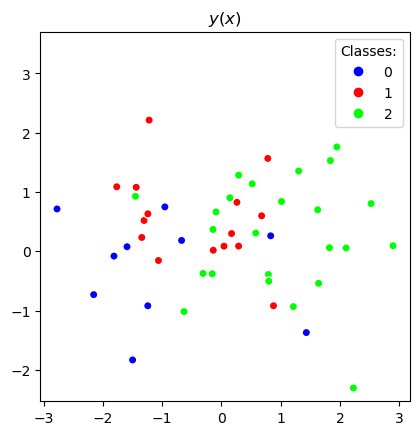

In [4]:
plt.legend(*plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='w').legend_elements(), title='Classes:')
plt.title('$y(x)$')
plt.axis('square')
plt.show()

***

### $k$-Nearest neighbors

In [67]:
import sklearn.base
from sklearn.utils.estimator_checks import check_estimator
from sklearn.utils.multiclass import unique_labels
from sklearn.utils.validation import check_is_fitted, validate_data


class KNearestNeighbors(sklearn.base.ClassifierMixin, sklearn.base.BaseEstimator):
    def __init__(self, k=3):
        self.k = k
    
    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = unique_labels(y)
        self.fitted_ = True
        # FIT HERE
        self.X_ = X
        self.y_ = (y[:, np.newaxis] == self.classes_)
        return self
            
    def predict_proba(self, X):
        check_is_fitted(self)
        X = validate_data(self, X, reset=False)
        # PREDICT PROBA HERE
#         print(X.shape, X[:, np.newaxis].shape)
#         print(self.X_.shape, self.X_[np.newaxis, :].shape)
        differences = X[:, np.newaxis] - self.X_[np.newaxis, :]
        sq_distances = np.sqrt(np.sum(differences**2, axis=-1))
        ordered = np.argpartition(sq_distances, self.k, axis=1)
        ordered = ordered[:, :self.k]
#         print(ordered.shape)
#         print(ordered)
        classes = self.y_[ordered]
#         print(classes.shape)
#         print(classes)
        y_proba = np.mean(classes, axis=1)
        
        return y_proba
            
    def predict(self, X):
        probas = self.predict_proba(X)
        return self.classes_[np.argmax(probas, axis=1)]
# check_estimator(KNearestNeighbors())

In [76]:
model = KNearestNeighbors(k=5)

model

,k,5


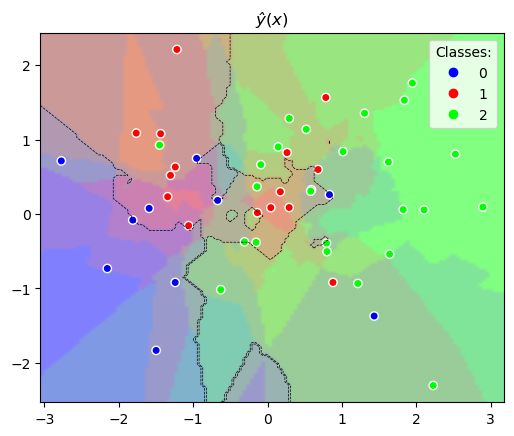

In [77]:
model.fit(X, y)
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

***

### Linear Discriminant Analysis

Bayes formula

$$
P(y | \boldsymbol{x}) \propto P(\boldsymbol{x} | y) \cdot P(y)
$$

Multivariate Gaussian distribution

$$
P(\boldsymbol{x} | y) = \sqrt{\left| \tfrac{1}{2 \pi} \boldsymbol{\Sigma}^{-1} \right|} e^{-\tfrac{1}{2} \left( \boldsymbol{x} - \boldsymbol{\mu}_y \right)^\text{T} \boldsymbol{\Sigma}^{-1} \left( \boldsymbol{x} - \boldsymbol{\mu}_y \right)}
$$

In [78]:
class LinearDA(sklearn.base.ClassifierMixin, sklearn.base.BaseEstimator):
    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = unique_labels(y)
        self.counts_ = np.count_nonzero(y[:, np.newaxis] == self.classes_, axis=0)
        self.means_ = {c: np.mean(X[y == c, :], axis=0) for c in self.classes_}
        cov = np.cov([x_i - self.means_[y_i] for x_i, y_i in zip(X, y)], ddof=0, rowvar=False)
        self.inv_cov_ = np.linalg.inv(cov)
        return self
            
    def predict_proba(self, X):
        X = validate_data(self, X, reset=False)
        check_is_fitted(self)
        y_proba = self.counts_ * np.exp([[-0.5 * (x_i - self.means_[y_i]) @ self.inv_cov_ @ (x_i - self.means_[y_i]) for y_i in self.classes_] for x_i in X])
        y_proba = y_proba / np.sum(y_proba, axis=1, keepdims=True)
        return y_proba
            
    def predict(self, X):
        probas = self.predict_proba(X)
        return self.classes_[np.argmax(probas, axis=1)]
# check_estimator(LinearDA())

In [79]:
model = LinearDA()

model

LinearDA()

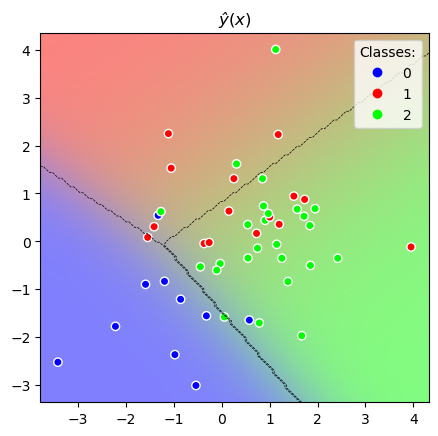

In [10]:
model.fit(X, y)
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

***

### Quadratic Discriminant Analysis

Bayes formula

$$
P(y | \boldsymbol{x}) \propto P(\boldsymbol{x} | y) \cdot P(y)
$$

Multivariate Gaussian distribution

$$
P(\boldsymbol{x} | y) = \sqrt{\left| \tfrac{1}{2 \pi} \boldsymbol{\Sigma}_y^{-1} \right|} e^{-\tfrac{1}{2} \left( \boldsymbol{x} - \boldsymbol{\mu}_y \right)^\text{T} \boldsymbol{\Sigma}_y^{-1} \left( \boldsymbol{x} - \boldsymbol{\mu}_y \right)}
$$

In [80]:
class QuadraticDA(sklearn.base.ClassifierMixin, sklearn.base.BaseEstimator):
    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = unique_labels(y)
        self.counts_ = np.count_nonzero(y[:, np.newaxis] == self.classes_, axis=0)
        self.means_ = {c: np.mean(X[y == c, :], axis=0) for c in self.classes_}
        self.inv_covs_ = {c: np.linalg.inv(np.cov([x_i - self.means_[y_i] for x_i, y_i in zip(X, y) if y_i == c], ddof=1, rowvar=False)) for c in self.classes_}
        return self
            
    def predict_proba(self, X):
        X = validate_data(self, X, reset=False)
        check_is_fitted(self)
        y_proba = self.counts_ * np.sqrt([np.linalg.det(self.inv_covs_[c]) for c in self.classes_]) * np.exp([[-0.5 * (x_i - self.means_[y_i]) @ self.inv_covs_[y_i] @ (x_i - self.means_[y_i]) for y_i in self.classes_] for x_i in X])
        y_proba = y_proba / np.sum(y_proba, axis=1, keepdims=True)
        return y_proba
            
    def predict(self, X):
        probas = self.predict_proba(X)
        return self.classes_[np.argmax(probas, axis=1)]

In [81]:
model = QuadraticDA()

model

QuadraticDA()

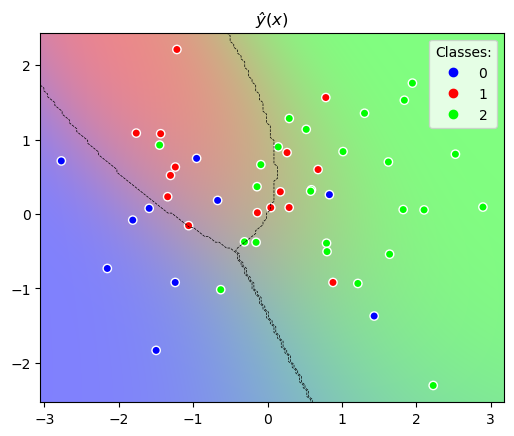

In [82]:
model.fit(X, y)
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

***

### Scikit-learn

In [14]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, y)

model

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


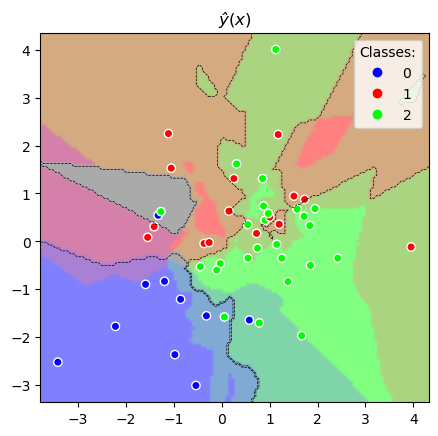

In [15]:
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

In [16]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
model = LinearDiscriminantAnalysis()
model.fit(X, y)

model

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


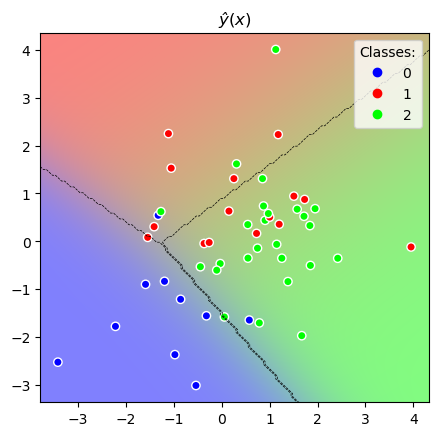

In [17]:
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

In [18]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
model = QuadraticDiscriminantAnalysis()
model.fit(X, y)

model

,priors,None
,reg_param,0.0
,store_covariance,False
,tol,0.0001


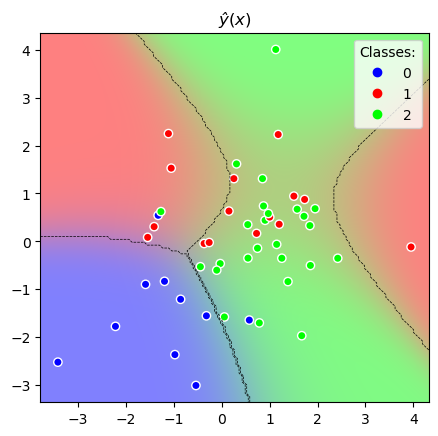

In [19]:
y_hat = model.predict(X)

y_hat
plot_decision_boundary(model, X, y)

In [88]:
from sklearn.svm import SVC
model = SVC(kernel='rbf')
model.fit(X, y)
model

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


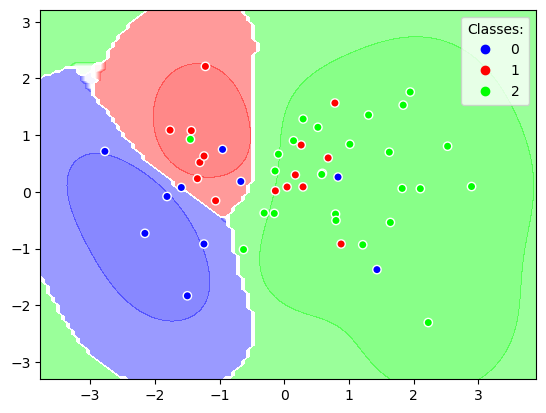

In [89]:
sklearn.inspection.DecisionBoundaryDisplay.from_estimator(model, X, multiclass_colors=plt.get_cmap().name, alpha=0.5)
plt.legend(*plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='w').legend_elements(), title='Classes:')


***

&copy; 2024 - Dave R.M. Langers <d.r.m.langers@pl.hanze.nl>